# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Fernanda Brittes, Willian e Gabriel · **Tema:** Estágio (chatbot "Estagi")

---

Notebook **entregável** do grupo. Roda do início ao fim ("Kernel → Restart & Run All")
e **regera os modelos** salvos em `modelos/`. Segue a estrutura do
`00_exemplo_biblioteca.ipynb`.

* `📝 RELATÓRIO` - resultado que aparece (e é discutido) no artigo.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# (só para o Colab) endereço do repositório do grupo
REPO_URL = "https://github.com/willfeerr/Est-gio-IA-2026-02-TP-Chatbot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO
from chatbot.texto import normalizar

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

---
## 1. Configuração

Tema **Estágio**: o bot atende estudantes de graduação da UFMS. As 8 intenções
foram definidas a partir dos assuntos do Regulamento de Estágio (Resolução nº
706-COGRAD/UFMS/2022) e da Lei nº 11.788/2008, procurando fronteiras que uma pessoa
consiga rotular sem hesitar.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema, "| limiar_tema:", config.limiar_tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Grupo Estágio | Tema: Estágio | limiar_tema: 0.3


,intenção,descrição
0,tipos_estagio,estágio obrigatório e não obrigatório e quem pode estagiar
1,vagas_convenio,"vagas de estágio, empresas concedentes, convênios e agentes de integração"
2,termo_compromisso,"termo de compromisso (TCE), assinaturas, termo aditivo e rescisão"
3,carga_horaria,"jornada, carga horária, duração máxima e recesso do estágio"
4,bolsa_auxilio,"bolsa, remuneração e auxílio-transporte"
5,seguro,seguro contra acidentes pessoais do estagiário
6,orientador_supervisor,"professor orientador, supervisor de estágio e Comissão de Estágio (COE)"
7,relatorio_avaliacao,"relatórios de atividades, avaliação e conclusão do estágio"


---
## 2. Dados

**Como os dados foram construídos** (detalhes no artigo e em `dados/README.md`):

* **LLM (`origem = llm`)** - `openai/gpt-6-luna` via OpenRouter, com
  `scripts/gerar_dados_llm.py` (5 estilos × 14 frases por intenção, chitchat e
  fora_dominio) e `scripts/gerar_negativos_dificeis.py` (perguntas dos **temas dos
  outros grupos** que usam palavras do nosso tema: *bolsa, termo, seguro, carga
  horária, relatório, orientador, convênio...*). Todos os prompts estão em
  `dados/prompts_llm.md`. **Todas** as frases foram revisadas; as descartadas e o
  motivo estão em `dados/descartadas_llm.txt`.
* **MASSIVE (`origem = massive`)** - amostra de 28 chitchat e 30 fora_dominio
  (`scripts/baixar_massive.py`): negativos fáceis, em português de Portugal.
* **Humano (`origem = humano`)** - 133 frases do formulário (Google Forms) respondido
  por colegas e escritas pelos integrantes (`dados/humano_treino.csv`).
* **Proporção humana ≥ 20%:** para cumprir a regra sem inventar dados, o treino usa
  **todas** as frases humanas e uma **amostra** das artificiais (41 do LLM por
  intenção, 53 chitchat e 92 fora_dominio do LLM), ficando com o mínimo exigido por
  classe (≥ 50 por intenção, ≥ 100 chitchat, ≥ 150 fora_dominio) e 20,1% humano.
* **Teste** - somente frases escritas por pessoas (`dados/humano_teste.csv`),
  separadas do treino antes de qualquer experimento.

`scripts/montar_treino.py` junta as fontes, remove duplicatas e garante que
nenhuma frase do teste esteja no treino.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
TEM_TESTE = len(teste) > 0
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
if TEM_TESTE:
    print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
    print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
else:
    print("ATENÇÃO: dados/teste.csv ainda está vazio (aguardando o formulário).")
display(resumo(treino))
if TEM_TESTE:
    display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,massive,total
intencao,,,,
bolsa_auxilio,10,40,0,50
carga_horaria,10,41,0,51
chitchat,21,51,28,100
fora_dominio,30,92,30,152
orientador_supervisor,10,41,0,51
relatorio_avaliacao,11,41,0,52
seguro,11,41,0,52
termo_compromisso,10,41,0,51
tipos_estagio,10,41,0,51


origem,humano,total
intencao,,
bolsa_auxilio,15,15
carga_horaria,15,15
chitchat,30,30
fora_dominio,40,40
orientador_supervisor,15,15
relatorio_avaliacao,15,15
seguro,15,15
termo_compromisso,15,15
tipos_estagio,15,15


### 2.1 Análise exploratória

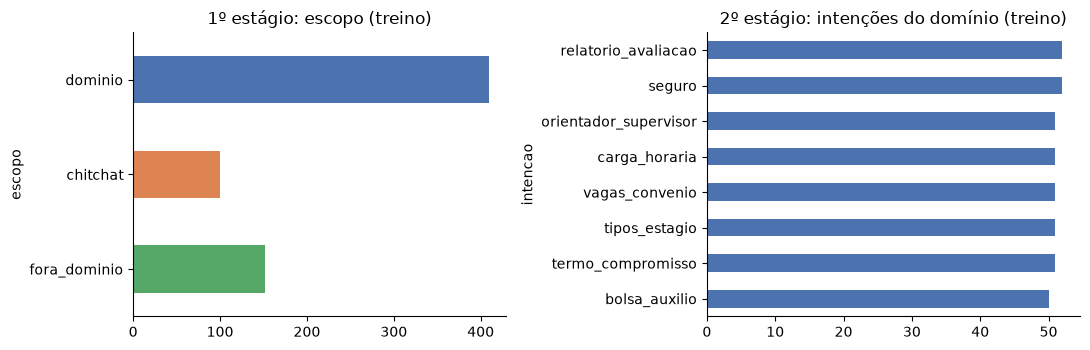

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)")
eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções do domínio (treino)")
eixos[1].invert_yaxis()
plt.tight_layout()
plt.show()

In [6]:
# tamanho das mensagens (em palavras) por classe e por origem
treino = treino.assign(n_palavras=treino["texto"].str.split().str.len())
display(treino.groupby("intencao")["n_palavras"].describe()[["mean", "50%", "min", "max"]].round(1))
display(treino.groupby("origem")["n_palavras"].describe()[["count", "mean", "50%"]].round(1))

,mean,50%,min,max
intencao,,,,
bolsa_auxilio,9.9,9.0,2.0,21.0
carga_horaria,11.6,10.0,3.0,28.0
chitchat,4.9,4.0,1.0,21.0
fora_dominio,9.9,9.5,2.0,23.0
orientador_supervisor,11.2,10.0,3.0,23.0
relatorio_avaliacao,10.7,10.0,3.0,23.0
seguro,10.5,10.0,3.0,20.0
termo_compromisso,11.2,10.0,3.0,24.0
tipos_estagio,9.7,10.0,2.0,19.0


,count,mean,50%
origem,,,
humano,133.0,7.3,8.0
llm,470.0,10.8,10.0
massive,58.0,6.8,6.0


In [7]:
# palavras mais frequentes por intenção (sem stopwords, sem acento)
from collections import Counter

from chatbot.texto import STOPWORDS

def top_palavras(textos, k=8):
    c = Counter(w for t in textos for w in normalizar(t).split() if w not in STOPWORDS and len(w) > 2)
    return ", ".join(w for w, _ in c.most_common(k))

pd.DataFrame({"palavras mais frequentes": treino.groupby("intencao")["texto"].apply(top_palavras)})

,palavras mais frequentes
intencao,
bolsa_auxilio,"bolsa, valor, auxilio, transporte, pode, pagamento, mes, nao"
carga_horaria,"estagio, horas, recesso, posso, limite, pode, dia, tempo"
chitchat,"bom, dia, voce, sobre, hoje, entendi, ate, valeu"
fora_dominio,"como, qual, preciso, algum, nao, posso, quais, auxilio"
orientador_supervisor,"orientador, professor, supervisor, quem, estagio, nao, coe, pode"
relatorio_avaliacao,"relatorio, como, estagio, final, atividades, posso, avaliacao, devo"
seguro,"seguro, acidente, cobre, cobertura, acidentes, durante, como, estagio"
termo_compromisso,"tce, termo, como, assinatura, aditivo, mas, nao, quem"
tipos_estagio,"estagio, obrigatorio, pode, fazer, curso, nao, estagiar, graduacao"


In [8]:
# exemplos de negativos difíceis (fora_dominio com palavras típicas do tema)
gatilhos = ["bolsa", "termo", "seguro", "carga horaria", "relatorio", "orientador", "convenio", "auxilio"]
norm = treino["texto"].map(normalizar)
mask = (treino["intencao"] == "fora_dominio") & norm.apply(lambda t: any(g in t for g in gatilhos))
print(f"{mask.sum()} frases fora_dominio contêm palavras do tema. Exemplos:")
treino.loc[mask, ["texto", "origem"]].sample(12, random_state=RANDOM_STATE)

35 frases fora_dominio contêm palavras do tema. Exemplos:


,texto,origem
488,A universidade tem convênio com instituições que oferecem atividades válidas para comp...,llm
229,Qual seguro saúde vale mais a pena?,llm
477,"Oi, queria saber qual é o valor da bolsa do auxílio permanência e quando sai o resultado.",llm
456,Auxílio alimentação,llm
234,Existe algum auxílio-transporte para estudantes que precisam se deslocar até o campus?,llm
545,O termo de empréstimo precisa de assinatura ou basta confirmar no sistema?,llm
383,tem algum auxilio pra comprar livros da faculdade,llm
221,O termo de cadastro precisa de assinatura presencial ou posso assinar digitalmente?,llm
176,Relatório de pesquisa,llm
243,O professor orientador da equipe de natação já foi divulgado?,llm


---
## 3. Representações de texto

Três representações, todas com a normalização do código base (minúsculas, sem
acento, sem pontuação):

* **TF-IDF palavras (1-2 gramas)** - padrão de `tfidf_palavras()`;
* **TF-IDF palavras (só unigramas, min_df=2)** - vocabulário menor;
* **TF-IDF caracteres (2-5 gramas)** - robusto a erros de digitação ("estagio",
  "estájio", "tce").

In [9]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF palavras (unigramas)": lambda: tfidf_palavras(ngram_range=(1, 1), min_df=2),
    "TF-IDF caracteres": tfidf_caracteres,
}
corpus = treino["texto"].tolist()
for nome, rep in REPRESENTACOES.items():
    print(f"{nome:30s}: {rep().fit_transform(corpus).shape[1]:6d} dimensões")

TF-IDF palavras               :   5113 dimensões
TF-IDF palavras (unigramas)   :    615 dimensões


TF-IDF caracteres             :   9749 dimensões


---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

Quatro algoritmos × três representações, validação cruzada estratificada com 5
folds **só no treino**. Regressão logística, MLP e árvore de decisão foram vistos
em aula; Naive Bayes multinomial entra como um quarto candidato (caixa-preta
explicada no artigo).

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras (unigramas),Regressão logística,0.826,0.040,0.862,0.995
1,TF-IDF palavras (unigramas),Rede neural (MLP),0.810,0.033,0.852,0.999
2,TF-IDF caracteres,Regressão logística,0.809,0.047,0.856,0.998
3,TF-IDF palavras,Rede neural (MLP),0.792,0.055,0.840,1.000
4,TF-IDF caracteres,Rede neural (MLP),0.789,0.043,0.834,1.000
5,TF-IDF palavras,Regressão logística,0.745,0.061,0.814,1.000
6,TF-IDF palavras,Naive Bayes,0.742,0.050,0.809,1.000
7,TF-IDF caracteres,Naive Bayes,0.727,0.034,0.805,0.981
8,TF-IDF palavras (unigramas),Naive Bayes,0.720,0.044,0.800,0.904
9,TF-IDF palavras (unigramas),Árvore de decisão,0.677,0.063,0.741,0.999


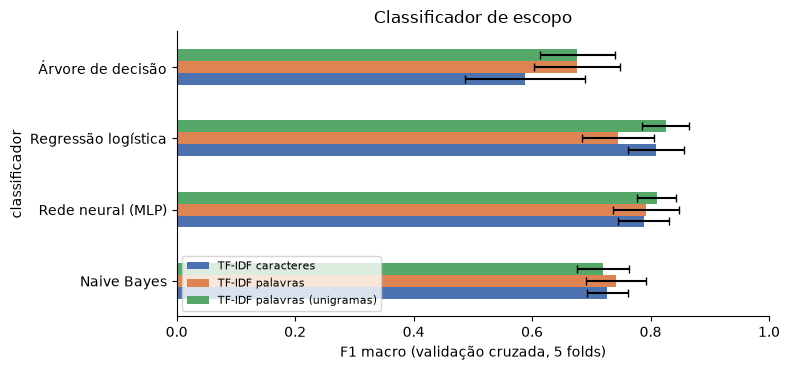

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": lambda: MultinomialNB(alpha=0.1),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


def grafico_comparacao(tab, titulo):
    piv = tab.pivot(index="classificador", columns="representação", values="F1 macro (CV)")
    err = tab.pivot(index="classificador", columns="representação", values="desvio")
    ax = piv.plot.barh(xerr=err, color=CORES[:3], figsize=(8, 3.8), capsize=3)
    ax.set_xlabel("F1 macro (validação cruzada, 5 folds)")
    ax.set_xlim(0, 1)
    ax.set_title(titulo)
    ax.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.show()


tab_escopo = comparar(treino["texto"], treino["escopo"])
display(tab_escopo.round(3))
grafico_comparacao(tab_escopo, "Classificador de escopo")

### 4.1 Ajuste de hiperparâmetros e curva de validação

Ajustamos os dois melhores algoritmos com `GridSearchCV` (só no treino): regressão
logística (C e faixa de n-gramas) e MLP (tamanho da camada e regularização α).

In [11]:
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=3000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, return_train_score=True, n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
print("Regressão logística:", busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

busca_escopo_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),
              ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
    param_grid={"classificador__hidden_layer_sizes": [(32,), (64,)],
                "classificador__alpha": [1e-4, 1e-2, 1]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_escopo_mlp.fit(treino["texto"], treino["escopo"])
print("MLP:", busca_escopo_mlp.best_params_, round(busca_escopo_mlp.best_score_, 3))

Regressão logística: {'classificador__C': 100, 'vetorizador__ngram_range': (2, 5)} 0.821


MLP: {'classificador__alpha': 1, 'classificador__hidden_layer_sizes': (32,)} 0.815


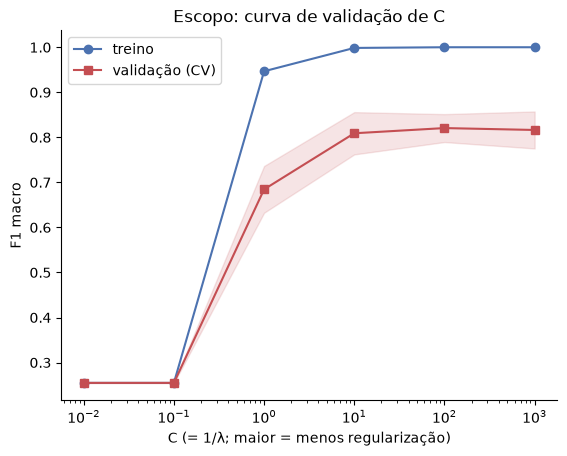

In [12]:
def curva_validacao(busca, titulo, filtro=None):
    res = pd.DataFrame(busca.cv_results_)
    if filtro:
        for k, v in filtro.items():
            res = res[res[k].astype(str) == str(v)]
    c = res["param_classificador__C"].astype(float)
    ax = plt.gca()
    ax.semilogx(c, res["mean_train_score"], "o-", color=CORES[0], label="treino")
    ax.semilogx(c, res["mean_test_score"], "s-", color=CORES[3], label="validação (CV)")
    ax.fill_between(c, res["mean_test_score"] - res["std_test_score"],
                    res["mean_test_score"] + res["std_test_score"], color=CORES[3], alpha=0.15)
    ax.set_xlabel("C (= 1/λ; maior = menos regularização)")
    ax.set_ylabel("F1 macro")
    ax.set_title(titulo)
    ax.legend()
    plt.show()


curva_validacao(busca_escopo, "Escopo: curva de validação de C",
                {"param_vetorizador__ngram_range": busca_escopo.best_params_["vetorizador__ngram_range"]})

In [13]:
# escolha do modelo final de escopo: o de maior F1 macro na CV
clf_escopo = (busca_escopo if busca_escopo.best_score_ >= busca_escopo_mlp.best_score_
              else busca_escopo_mlp).best_estimator_
print("Escopo escolhido:", clf_escopo.named_steps["classificador"])

Escopo escolhido: LogisticRegression(C=100, max_iter=3000)


### 4.2 Matriz de confusão, falso aceite e falsa recusa

📝 RELATÓRIO: no tema estágio, o **falso aceite** (responder com regras de estágio
uma pergunta sobre bolsa de monitoria, auxílio da assistência estudantil ou
orientador de TCC) é o erro mais grave: o estudante recebe uma regra **errada**
com confiança, por exemplo sobre valor de bolsa ou prazo. A **falsa recusa** só
faz o estudante reformular ou procurar a COE.

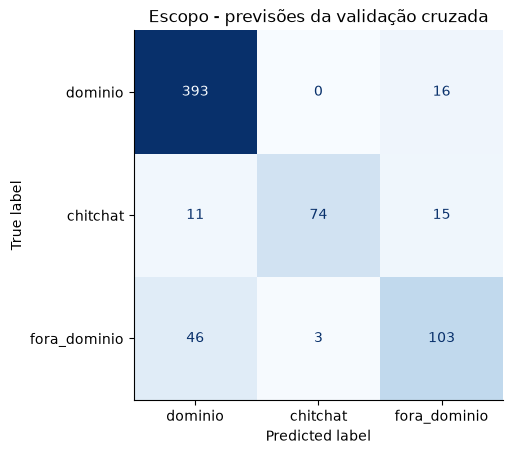

falso aceite  (neg. previstos como dominio): 0.226
falsa recusa  (dominio previsto como outro): 0.039

Erros por origem:


,erros,total,taxa
origem,,,
llm,48,470,0.102
humano,25,133,0.188
massive,18,58,0.310


,texto,escopo,previsto,origem
5,essa resposta ta meio estranha,chitchat,dominio,humano
11,Bom dia! Estou tentando terminar esse trabalho antes do prazo e mal consigo pensar dir...,chitchat,dominio,llm
47,"Você é muito paciente comigo, ainda mais com esse meu desespero de véspera de prova.",chitchat,fora_dominio,llm
68,A bolsa alimentação dá direito a refeições gratuitas ou tem algum valor por refeição?,fora_dominio,dominio,llm
71,"fiz uma palestra online e perdi o certificado, tem como validar as horas com outro doc...",fora_dominio,dominio,llm
...,...,...,...,...
603,Perdi as chaves de casa e meu colega de apartamento não atende. O que devo fazer agora?,fora_dominio,dominio,llm
623,o que posso fazer com portátil,fora_dominio,dominio,massive
628,gostaria que ajudasse com depuração do código,chitchat,fora_dominio,massive
642,recapitula o meu dia,chitchat,fora_dominio,massive


In [14]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.title("Escopo - previsões da validação cruzada")
plt.grid(False)
plt.show()

real = treino["escopo"].to_numpy()
neg = real != "dominio"
print(f"falso aceite  (neg. previstos como dominio): {(prev_cv[neg] == 'dominio').mean():.3f}")
print(f"falsa recusa  (dominio previsto como outro): {(prev_cv[~neg] != 'dominio').mean():.3f}")
erros_escopo = treino.assign(previsto=prev_cv).query("escopo != previsto")
print("\nErros por origem:")
display(erros_escopo["origem"].value_counts().to_frame("erros").join(treino["origem"].value_counts().rename("total"))
        .assign(taxa=lambda d: (d["erros"] / d["total"]).round(3)))
erros_escopo[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

Mesma metodologia, treinando **só** com as mensagens do domínio.

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Naive Bayes,0.942,0.013,0.944,0.998
1,TF-IDF caracteres,Regressão logística,0.940,0.019,0.941,1.000
2,TF-IDF palavras,Regressão logística,0.940,0.021,0.941,1.000
3,TF-IDF caracteres,Rede neural (MLP),0.935,0.015,0.936,1.000
4,TF-IDF palavras,Naive Bayes,0.927,0.018,0.929,1.000
5,TF-IDF palavras (unigramas),Regressão logística,0.920,0.037,0.922,1.000
6,TF-IDF palavras (unigramas),Rede neural (MLP),0.911,0.035,0.912,1.000
7,TF-IDF palavras,Rede neural (MLP),0.907,0.015,0.907,1.000
8,TF-IDF palavras (unigramas),Naive Bayes,0.890,0.032,0.890,0.996
9,TF-IDF palavras (unigramas),Árvore de decisão,0.863,0.022,0.863,1.000


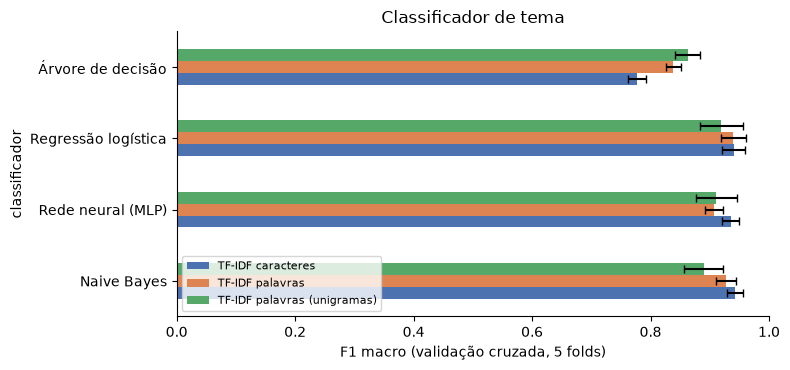

In [15]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
display(tab_tema.round(3))
grafico_comparacao(tab_tema, "Classificador de tema")

Regressão logística: {'classificador__C': 100, 'vetorizador__ngram_range': (2, 5)} 0.943


MLP: {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (64,)} 0.945


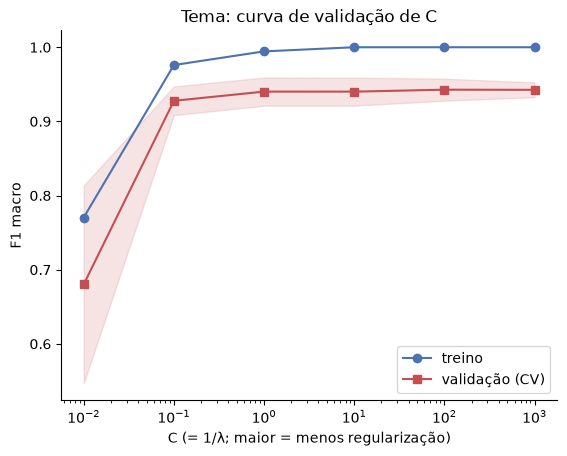

Tema escolhido: MLPClassifier(alpha=0.01, hidden_layer_sizes=(64,), max_iter=600,
              random_state=42)


In [16]:
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=3000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, return_train_score=True, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
print("Regressão logística:", busca_tema.best_params_, round(busca_tema.best_score_, 3))

busca_tema_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),
              ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
    param_grid={"classificador__hidden_layer_sizes": [(32,), (64,)],
                "classificador__alpha": [1e-4, 1e-2, 1]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema_mlp.fit(treino_dom["texto"], treino_dom["intencao"])
print("MLP:", busca_tema_mlp.best_params_, round(busca_tema_mlp.best_score_, 3))

curva_validacao(busca_tema, "Tema: curva de validação de C",
                {"param_vetorizador__ngram_range": busca_tema.best_params_["vetorizador__ngram_range"]})

clf_tema = (busca_tema if busca_tema.best_score_ >= busca_tema_mlp.best_score_
            else busca_tema_mlp).best_estimator_
print("Tema escolhido:", clf_tema.named_steps["classificador"])

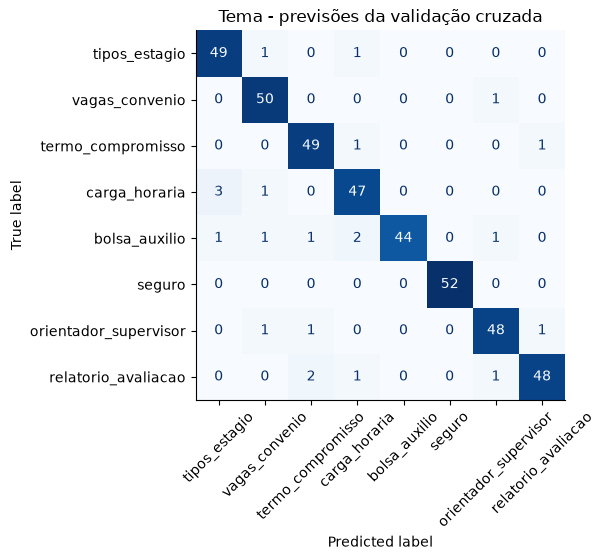

                       precision    recall  f1-score   support

        bolsa_auxilio       1.00      0.88      0.94        50
        carga_horaria       0.90      0.92      0.91        51
orientador_supervisor       0.94      0.94      0.94        51
  relatorio_avaliacao       0.96      0.92      0.94        52
               seguro       1.00      1.00      1.00        52
    termo_compromisso       0.92      0.96      0.94        51
        tipos_estagio       0.92      0.96      0.94        51
       vagas_convenio       0.93      0.98      0.95        51

             accuracy                           0.95       409
            macro avg       0.95      0.95      0.95       409
         weighted avg       0.95      0.95      0.95       409



In [17]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Tema - previsões da validação cruzada")
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

In [18]:
# 📝 RELATÓRIO: pares de intenções que mais se confundem
pares = (treino_dom.assign(previsto=prev_tema).query("intencao != previsto")
         .groupby(["intencao", "previsto"]).size().sort_values(ascending=False).head(8))
display(pares.to_frame("erros"))
treino_dom.assign(previsto=prev_tema).query("intencao != previsto")[["texto", "intencao", "previsto"]]

erros
intencao              previsto                    
carga_horaria         tipos_estagio              3
bolsa_auxilio         carga_horaria              2
relatorio_avaliacao   termo_compromisso          2
bolsa_auxilio         orientador_supervisor      1
                      tipos_estagio              1
                      termo_compromisso          1
carga_horaria         vagas_convenio             1
orientador_supervisor relatorio_avaliacao        1

,texto,intencao,previsto
67,Estagiário pode fazer 8h por dia?,carga_horaria,tipos_estagio
70,Posso estagiar de manhã e estudar à tarde?,carga_horaria,tipos_estagio
83,É necessário entregar uma via do TCE para cada parte envolvida?,termo_compromisso,relatorio_avaliacao
105,a assinatura de quem vale na ficha de frequencia?,orientador_supervisor,termo_compromisso
132,Quanto vou receber?,bolsa_auxilio,termo_compromisso
179,o recesso precisa ser marcado junto com as ferias da faculdade,carga_horaria,vagas_convenio
180,"Caso haja atraso no pagamento, qual canal devo procurar para obter orientação?",bolsa_auxilio,orientador_supervisor
194,o supervisor tb preenche o relatorio?,relatorio_avaliacao,orientador_supervisor
246,Há algum procedimento para confirmar que a documentação de conclusão do estágio foi re...,relatorio_avaliacao,termo_compromisso
253,preciso de assinatura da empresa no relatorio?,relatorio_avaliacao,termo_compromisso


In [19]:
# termos de maior peso por intenção (modelo interpretável: logística com TF-IDF de palavras)
interpretavel = Pipeline([("vetorizador", tfidf_palavras()),
                          ("classificador", LogisticRegression(C=10, max_iter=2000))])
interpretavel.fit(treino_dom["texto"], treino_dom["intencao"])
termos = interpretavel["vetorizador"].get_feature_names_out()
pesos = interpretavel["classificador"].coef_
pd.DataFrame({c: [termos[j] for j in np.argsort(pesos[i])[::-1][:8]]
              for i, c in enumerate(interpretavel["classificador"].classes_)})

,bolsa_auxilio,carga_horaria,orientador_supervisor,relatorio_avaliacao,seguro,termo_compromisso,tipos_estagio,vagas_convenio
0,bolsa,horas,orientador,relatorio,seguro,tce,obrigatorio,vagas
1,transporte,recesso,supervisor,final,acidente,termo,estagio,universidade
2,valor,limite,coe,avaliacao,cobre,assinatura,fazer estagio,convenio
3,auxilio,jornada,professor,no relatorio,um acidente,termo de,estagio obrigatorio,empresas
4,pagamento,carga horaria,professor orientador,atividades,cobertura,aditivo,estagiar,oportunidades
5,da bolsa,horaria,meu,conclusao,seguro cobre,de compromisso,fazer,uma
6,auxilio transporte,carga,quem,conclusao do,meu seguro,compromisso,curso,uma empresa
7,remunerado,duracao,do supervisor,do estagio,apolice,rescisao,graduacao,empresa


---
## 6. Limiar de confiança

Probabilidades da validação cruzada: para cada limiar, quantas frases o bot
responderia direto, com que acurácia, quantos erros evitaria e quantos acertos
viraria pergunta ("sua dúvida é sobre X ou Y?").

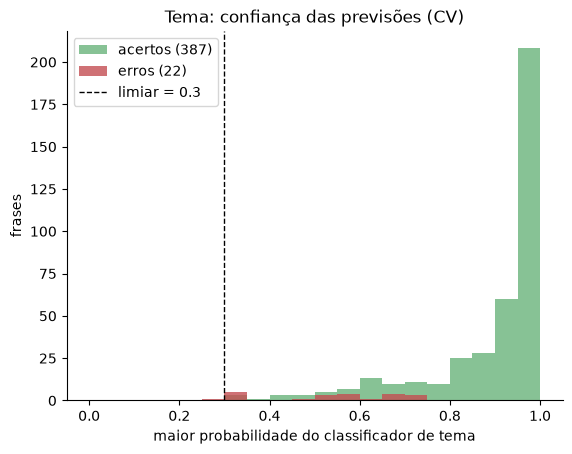

,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.946,0,0
1,0.20,1.000,0.946,0,0
2,0.25,1.000,0.946,0,0
3,0.30,0.998,0.949,1,0
4,0.35,0.978,0.960,6,3
5,0.40,0.976,0.960,6,4
6,0.50,0.958,0.962,7,10
7,0.60,0.912,0.979,14,22


In [20]:
proba_cv = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv,
                             method="predict_proba")
classes = np.array(sorted(treino_dom["intencao"].unique()))
confianca = proba_cv.max(axis=1)
acertou = classes[proba_cv.argmax(axis=1)] == treino_dom["intencao"].to_numpy()

bins = np.linspace(0, 1, 21)
plt.hist(confianca[acertou], bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
plt.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
plt.axvline(config.limiar_tema, color="k", ls="--", lw=1, label=f"limiar = {config.limiar_tema}")
plt.xlabel("maior probabilidade do classificador de tema")
plt.ylabel("frases")
plt.title("Tema: confiança das previsões (CV)")
plt.legend()
plt.show()

linhas = []
for limiar in [0.0, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]:
    resp = confianca >= limiar
    linhas.append({"limiar": limiar, "% respondidas direto": resp.mean(),
                   "acurácia nas respondidas": acertou[resp].mean() if resp.any() else np.nan,
                   "erros evitados": int((~acertou & ~resp).sum()),
                   "acertos que viraram pergunta": int((acertou & ~resp).sum())})
tab_limiar = pd.DataFrame(linhas)
tab_limiar.round(3)

**Escolha do limiar.** O valor gravado em `roteamento.limiar_tema` (grupo.yaml) é o
que troca a maior quantidade de erros por perguntas sem transformar muitos acertos
em perguntas (ver tabela acima; a justificativa numérica está no artigo). Na
avaliação automática, uma pergunta de esclarecimento conta como erro, por isso o
limiar é conservador.

---
## 7. Salvar os modelos finais

In [21]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado
print("Salvos em:", config.modelo_escopo.parent, "| limiar_tema =", config.limiar_tema)

Salvos em: C:\Users\GABRI\OneDrive\Documentos\UFMS\IA\TRABALHO\Est-gio-IA-2026-02-TP-Chatbot\modelos | limiar_tema = 0.3


---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

Documentos em `documentos/` (uma pasta por intenção + `geral/`, fontes em
`documentos/FONTES.md`): Resolução 706-COGRAD, manual do Termo de Compromisso,
IN 11-PROAES (seguro), manual de estágio do CPAQ e resumos escritos pelo grupo a
partir da Lei 11.788/2008. A persona ("Estagi") manda responder só com base nos
trechos e indicar a COE quando não souber.

In [22]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)
display(base.resumo())

# teste da busca (não gasta créditos)
for pergunta, intencao in [("quantas horas por dia posso estagiar?", "carga_horaria"),
                           ("quem paga o seguro no estágio não obrigatório?", "seguro"),
                           ("passou do prazo do termo, posso fazer aditivo?", "termo_compromisso")]:
    print(f"\n>>> {pergunta}  [{intencao}]")
    for tr, sim in base.buscar(pergunta, intencao=intencao, k=3):
        print(f"  {sim:.2f}  {tr.fonte} | {tr.texto[:70]!r}")

trechos  \
intencao              fonte                                                                   
bolsa_auxilio         bolsa_auxilio\bolsa_e_auxilio_transporte.md                         8   
carga_horaria         carga_horaria\jornada_duracao_recesso.md                            6   
geral                 geral\perguntas_frequentes_estagio.md                               4   
                      geral\resolucao_706_cograd_2022_regulamento_estagio.pdf            44   
orientador_supervisor orientador_supervisor\orientador_supervisor_coe.md                  6   
relatorio_avaliacao   relatorio_avaliacao\manual_estagio_matematica_cpaq.pdf             15   
                      relatorio_avaliacao\relatorios_e_avaliacao.md                       5   
seguro                seguro\instrucao_normativa_11_proaes_2021_seguro.pdf                9   
                      seguro\seguro_do_estagiario.md                                      6   
termo_compromisso     termo_compromisso\manual_preenchimento_termo_compromisso.pdf       16   
                      termo_compromisso\termo_de_compromisso_passo_a_passo.md             8   
tipos_estagio         tipos_estagio\obrigatorio_e_nao_obrigatorio.md                      7   
vagas_convenio        vagas_convenio\vagas_e_convenios.md                                 6   

                                                                                    caracteres  
intencao              fonte                                                                     
bolsa_auxilio         bolsa_auxilio\bolsa_e_auxilio_transporte.md                         1688  
carga_horaria         carga_horaria\jornada_duracao_recesso.md                            1944  
geral                 geral\perguntas_frequentes_estagio.md                               2046  
                      geral\resolucao_706_cograd_2022_regulamento_estagio.pdf            23449  
orientador_supervisor orientador_supervisor\orientador_supervisor_coe.md                  2247  
relatorio_avaliacao   relatorio_avaliacao\manual_estagio_matematica_cpaq.pdf             10166  
                      relatorio_avaliacao\relatorios_e_avaliacao.md                       1809  
seguro                seguro\instrucao_normativa_11_proaes_2021_seguro.pdf                3980  
                      seguro\seguro_do_estagiario.md                                      1871  
termo_compromisso     termo_compromisso\manual_preenchimento_termo_compromisso.pdf        5862  
                      termo_compromisso\termo_de_compromisso_passo_a_passo.md             3318  
tipos_estagio         tipos_estagio\obrigatorio_e_nao_obrigatorio.md                      2483  
vagas_convenio        vagas_convenio\vagas_e_convenios.md                                 2369


>>> quantas horas por dia posso estagiar?  [carga_horaria]
  0.19  geral\perguntas_frequentes_estagio.md | 'Perguntas frequentes sobre estágio na UFMS\n**Estagiário tem carteira a'
  0.16  carga_horaria\jornada_duracao_recesso.md | 'Jornada diária e semanal\n- Para estudantes de graduação, a jornada de '
  0.15  carga_horaria\jornada_duracao_recesso.md | 'Carga horária do estágio obrigatório\nA carga horária total do estágio '

>>> quem paga o seguro no estágio não obrigatório?  [seguro]
  0.34  seguro\seguro_do_estagiario.md | 'O seguro é obrigatório\nTodo estágio, obrigatório ou não obrigatório, e'
  0.32  seguro\seguro_do_estagiario.md | 'Estágio não obrigatório: seguro da concedente\nNo estágio não obrigatór'
  0.28  seguro\seguro_do_estagiario.md | 'Estágio obrigatório: seguro da UFMS\nNo estágio obrigatório, a UFMS con'

>>> passou do prazo do termo, posso fazer aditivo?  [termo_compromisso]
  0.34  termo_compromisso\termo_de_compromisso_passo_a_passo.md | 'Prorrogação (Termo Ad

In [23]:
# o prompt que o LLM recebe para uma pergunta
pergunta, intencao = "quantas horas por dia posso estagiar?", "carga_horaria"
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content'][:1200]}\n")

--- system ---
Você é o Estagi, assistente virtual de estágios dos cursos de graduação da UFMS. Fale de forma cordial, simples e direta, tratando o estudante por "você". Responda somente com base nos trechos dos documentos fornecidos; se a informação não estiver neles, diga que não sabe e indique o contato. Nunca invente valores, prazos ou datas. Lembre que regras específicas podem variar conforme o Projeto Pedagógico de cada curso.

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira a Comissão de Estágio (COE) do seu curso ou o e-mail estagio@ufms.br.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: jornada, carga horária, duração máxima e

In [24]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
mensagens = [
    "oi, bom dia!",
    "posso fazer estágio no primeiro semestre?",
    "quantas horas por semana o estagiario pode trabalhar",
    "a empresa é obrigada a pagar bolsa no estágio não obrigatório?",
    "quem paga o seguro?",
    "meu termo de compromisso venceu semana passada, ainda dá pra prorrogar?",
    "qual o valor da bolsa de monitoria?",          # negativo difícil
    "qual o telefone da COE de Ciência da Computação?",  # resposta NÃO está nos documentos
    "valeu, tchau",
]
for m in mensagens:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [escopo={e['escopo']} | rota={e['rota']} | resposta {e['fonte_resposta']}]\n"
          f"  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi, bom dia!
  [escopo=chitchat | rota=chitchat | resposta llm]
  bot: Oi, bom dia! Como posso ajudar você com seu estágio na UFMS?



você: posso fazer estágio no primeiro semestre?
  [escopo=dominio | rota=tipos_estagio | resposta llm]
  bot: Você pode fazer estágio não obrigatório, em geral, desde o primeiro ano, se o PPC do seu curso não disser o contrário. Para confirmar se é permitido já no primeiro semestre, consulte a COE do seu curso. [fontes: tipos_estagio\obrigatorio_e_nao_obrigatorio.md]



você: quantas horas por semana o estagiario pode trabalhar
  [escopo=dominio | rota=carga_horaria | resposta llm]
  bot: A jornada é de até 30 horas por semana. Nos períodos sem aulas presenciais, pode chegar a 40 horas semanais se o PPC do curso permitir. [fonte: carga_horaria\jornada_duracao_recesso.md]



você: a empresa é obrigada a pagar bolsa no estágio não obrigatório?
  [escopo=dominio | rota=bolsa_auxilio | resposta llm]
  bot: Sim. No estágio não obrigatório, a concedente deve pagar bolsa ou outra forma de contraprestação e também auxílio-transporte. [fonte: bolsa_auxilio\bolsa_e_auxilio_transporte.md]



você: quem paga o seguro?
  [escopo=dominio | rota=seguro | resposta llm]
  bot: No estágio não obrigatório, quem paga/contrata o seguro é a concedente; no obrigatório, a UFMS contrata a seguradora, e a Proaes faz a gestão. [fonte: seguro\seguro_do_estagiario.md]

você: meu termo de compromisso venceu semana passada, ainda dá pra prorrogar?
  [escopo=fora_dominio | rota=fora_dominio | resposta fixa]
  bot: Desculpe, só sei responder sobre estágio: estágio obrigatório e não obrigatório e quem pode estagiar, vagas de estágio, empresas concedentes, convênios e agentes de integração, termo de compromisso (TCE), assinaturas, termo aditivo e rescisão, jornada, carga horária, duração máxima e recesso do estágio, bolsa, remuneração e auxílio-transporte, seguro contra acidentes pessoais do estagiário, professor orientador, supervisor de estágio e Comissão de Estágio (COE) e relatórios de atividades, avaliação e conclusão do estágio. Para outros assuntos, procure a secretaria acadêmica ou a coor

você: qual o valor da bolsa de monitoria?
  [escopo=dominio | rota=bolsa_auxilio | resposta llm]
  bot: Os trechos não informam o valor da bolsa de monitoria, que tem edital próprio. Não tenho essa informação; você pode consultar a COE do seu curso ou escrever para estagio@ufms.br. [fonte: bolsa_auxilio\bolsa_e_auxilio_transporte.md]

você: qual o telefone da COE de Ciência da Computação?
  [escopo=fora_dominio | rota=fora_dominio | resposta fixa]
  bot: Desculpe, só sei responder sobre estágio: estágio obrigatório e não obrigatório e quem pode estagiar, vagas de estágio, empresas concedentes, convênios e agentes de integração, termo de compromisso (TCE), assinaturas, termo aditivo e rescisão, jornada, carga horária, duração máxima e recesso do estágio, bolsa, remuneração e auxílio-transporte, seguro contra acidentes pessoais do estagiário, professor orientador, supervisor de estágio e Comissão de Estágio (COE) e relatórios de atividades, avaliação e conclusão do estágio. Para outros a

você: valeu, tchau
  [escopo=chitchat | rota=chitchat | resposta llm]
  bot: Por nada! Tchau, e conte comigo se precisar de ajuda com estágio.

Uso do LLM: {'chamadas': 7, 'tokens_entrada': 5411, 'tokens_saida': 697}


---
## 9. Aprofundamento A1 - cascata (2 estágios) × classificador único

Comparamos, por validação cruzada no treino (e no teste, se disponível), o
**pipeline em cascata** (escopo → tema, sem limiar) com **um único classificador**
de N+2 classes (8 intenções + chitchat + fora_dominio), ambos com a mesma
representação e o mesmo algoritmo (TF-IDF de caracteres + regressão logística).
A métrica é o F1 macro ponta a ponta sobre as 10 classes.

In [25]:
def cascata_prever(m_escopo, m_tema, textos):
    esc = m_escopo.predict(textos)
    tema = m_tema.predict(textos)
    return np.where(esc == "dominio", tema, esc)


def comparar_cascata(treino_df, teste_df=None, C_escopo=None, C_tema=None):
    base_pipe = Pipeline([("vetorizador", tfidf_caracteres()),
                          ("classificador", LogisticRegression(max_iter=3000))])
    y = treino_df["intencao"].to_numpy()
    X = treino_df["texto"].to_numpy()
    esc = treino_df["escopo"].to_numpy()
    res = {"cascata": [], "único (N+2 classes)": []}
    for tr, va in cv.split(X, y):
        m_esc = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X[tr], esc[tr])
        dom = esc[tr] == "dominio"
        m_tema = clone(base_pipe).set_params(classificador__C=C_tema).fit(X[tr][dom], y[tr][dom])
        res["cascata"].append(f1_score(y[va], cascata_prever(m_esc, m_tema, X[va]), average="macro"))
        m_uni = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X[tr], y[tr])
        res["único (N+2 classes)"].append(f1_score(y[va], m_uni.predict(X[va]), average="macro"))
    linhas = [{"abordagem": k, "F1 macro (CV)": np.mean(v), "desvio": np.std(v)} for k, v in res.items()]
    if teste_df is not None and len(teste_df):
        m_esc = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X, esc)
        m_tema = clone(base_pipe).set_params(classificador__C=C_tema).fit(X[esc == "dominio"], y[esc == "dominio"])
        m_uni = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X, y)
        yt = teste_df["intencao"].to_numpy()
        linhas[0]["F1 macro (teste)"] = f1_score(yt, cascata_prever(m_esc, m_tema, teste_df["texto"]), average="macro")
        linhas[1]["F1 macro (teste)"] = f1_score(yt, m_uni.predict(teste_df["texto"]), average="macro")
    return pd.DataFrame(linhas)


C_esc = busca_escopo.best_params_["classificador__C"]
C_tem = busca_tema.best_params_["classificador__C"]
tab_a1 = comparar_cascata(treino, teste if TEM_TESTE else None, C_esc, C_tem)
tab_a1.round(3)

,abordagem,F1 macro (CV),desvio,F1 macro (teste)
0,cascata,0.853,0.017,0.849
1,único (N+2 classes),0.887,0.021,0.850


📝 RELATÓRIO: discussão no artigo - quando a cascata compensa (separação dos
erros, limiar só no tema, algoritmo próprio por estágio) e quando o classificador
único é equivalente.

---
## 10. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, falso aceite/falsa recusa, comparação com a
validação cruzada e análise dos erros por origem.

In [26]:
if TEM_TESTE:
    clf_escopo, clf_tema = carregar_classificadores(config)
    grafo = construir_grafo(config, clf_escopo, clf_tema)
    resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
    tab, extras = tabela_resumo(resultado)
    display(tab.round(3))
    display(extras.round(3))
    display(previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo",
                                                   "confianca_intencao"]])
else:
    print("Teste ainda não disponível: rode esta seção depois de preencher dados/humano_teste.csv")

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),190,0.895,0.853
"tema (2º estágio, oráculo)",120,0.933,0.933
ponta a ponta (grafo),190,0.847,0.878


falso aceite           0.100
falsa recusa           0.025
esclarecimentos        0.042
latência média (ms)    3.742
dtype: float64

,texto,real,rota,confianca_escopo,confianca_intencao
24,Poderia me responder de outra forma,chitchat,esclarecer,0.890355,0.269370
28,"Por favor, reveja meu pedido anterior e avalie se está de acordo com o que você entregou",chitchat,relatorio_avaliacao,0.783410,0.377104
48,posso fazer hora extra?,carga_horaria,fora_dominio,0.488098,0.000000
68,"gente, quem assina minha avaliação do estagio?",orientador_supervisor,relatorio_avaliacao,0.999944,0.515267
72,quem acompanha o aluno durante o estagio?,orientador_supervisor,esclarecer,0.999268,0.251661
73,se eu tiver problema com a empresa falo com quem??,orientador_supervisor,vagas_convenio,0.976615,0.399959
75,Estágio benefícios,bolsa_auxilio,esclarecer,0.986229,0.219557
88,tem como receber algum auxilio fazendo estagio obrigatorio?,bolsa_auxilio,tipos_estagio,0.999455,0.619474
91,Como estagiar,vagas_convenio,tipos_estagio,0.999937,0.620680
98,qualquer empresa pode contratar estagiario?,vagas_convenio,bolsa_auxilio,0.999973,0.347691


---
## 11. Uso de IA generativa

Todo uso de IA do grupo (geração de dados, LLM do bot, código, documentos, escrita)
está em `USO_DE_IA.md`, copiado para a seção própria do artigo e mencionado no
vídeo.

---
## 12. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [27]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'Grupo Estágio', tema 'Estágio'
[ OK  ] 8 intenções definidas (exigido: 5 a 10)
[ OK  ] 3 integrante(s) com nome (exigido: 3 a 4)
[ OK  ] treino.csv: 661 mensagens, formato válido
[ OK  ] teste.csv: 190 mensagens, formato válido
[ OK  ] treino: mínimo de 50 exemplos por intenção
[ OK  ] treino: 100 exemplos de chitchat (mínimo 100)
[ OK  ] treino: 152 exemplos de fora_dominio (mínimo 150)
[ OK  ] treino: 20% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ OK  ] teste: mínimo de 15 exemplos por intenção
[ OK  ] teste: 30 exemplos de chitchat (mínimo 30)
[ OK  ] teste: 40 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ OK  ] classificadores carregados e com as classes corretas
[ OK  ] grafo responde e devolve 'rota' válida (20 mensagens testadas)
[ OK  ] 13 documento(s) na base de conhecimento (mínimo 5)
[ OK  ] todas as intenções têm docume